In [32]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

In [33]:
# Semilla
tf.keras.utils.set_random_seed(42)

In [34]:
# Cargar datos
def cargar_fashion_mnist(batch_size=32, shuffle=True):
    # Descargar arreglos base desde Keras
    (X_train, y_train), (X_test_full, y_test_full) = tf.keras.datasets.fashion_mnist.load_data()

    # Agregar dimensión de canal (28, 28) -> (28, 28, 1) igual que en tfds
    X_train = X_train[..., tf.newaxis]
    X_test_full = X_test_full[..., tf.newaxis]

    # Separar X_test_full en X_test y X_val
    # Separar y_test_full en y_test y y_val
    X_test, X_val, y_test, y_val= train_test_split(
        X_test_full, y_test_full, test_size=0.50, random_state=42
    )

    # 3. Convertir a tf.data.Dataset con formato as_supervised=True -> (imagen, etiqueta)
    ds_train = tf.data.Dataset.from_tensor_slices((X_train, y_train))
    ds_test = tf.data.Dataset.from_tensor_slices((X_test, y_test))
    ds_val = tf.data.Dataset.from_tensor_slices((X_val, y_val))

    # 4. Barajar (equivalente a shuffle_files=True) y agrupar en lotes (batch_size=32)
    if shuffle:
        ds_train = ds_train.shuffle(buffer_size=len(X_train), reshuffle_each_iteration=True)

    ds_train = ds_train.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    ds_test = ds_test.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    ds_val = ds_val.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return ds_train, ds_test, ds_val

In [35]:
ds_train, ds_test, ds_val = cargar_fashion_mnist(batch_size=32)

In [36]:
ds_train.element_spec

(TensorSpec(shape=(None, 28, 28, 1), dtype=tf.uint8, name=None),
 TensorSpec(shape=(None,), dtype=tf.uint8, name=None))

In [37]:
ds_train.take(1)

<_TakeDataset element_spec=(TensorSpec(shape=(None, 28, 28, 1), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.uint8, name=None))>

In [38]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

def imprimir_imagenes_lote(batch):
    images_batch, labels_batch = next(iter(batch))
    # imprimir forma y rango de valores
    print(f"Forma del lote: {images_batch.shape} | Rango: [{images_batch.numpy().min():.2f}, {images_batch.numpy().max():.2f}]")
    
    # Visualizar las imágenes
    plt.figure(figsize=(8,8))
    num_images = min(9, images_batch.shape[0])

    for i in range(num_images):
        ax = plt.subplot(3, 3, i+1)
        img = images_batch[i].numpy().squeeze()
        label_idx = int(labels_batch[i].numpy())

        plt.imshow(img, cmap='gray')
        plt.title(f"{label_idx}: {class_names[label_idx]}")
        plt.axis("off")


Forma del lote: (32, 28, 28, 1) | Rango: [0.00, 255.00]


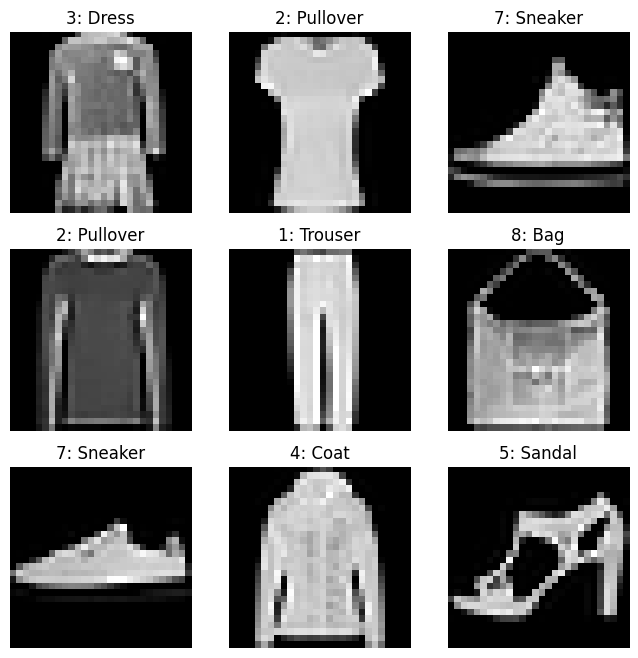

In [39]:
imprimir_imagenes_lote(ds_train.take(1))

Forma del lote: (32, 28, 28, 1) | Rango: [0.00, 255.00]


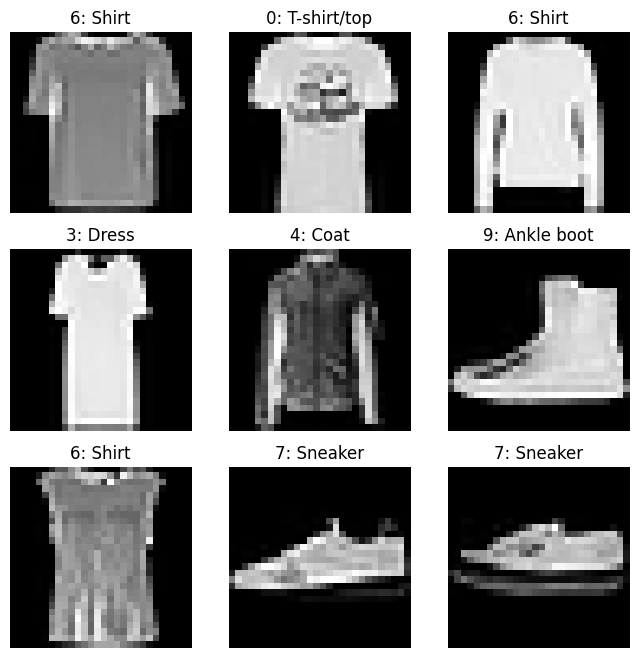

In [40]:
imprimir_imagenes_lote(ds_test.take(2))

Forma del lote: (32, 28, 28, 1) | Rango: [0.00, 255.00]


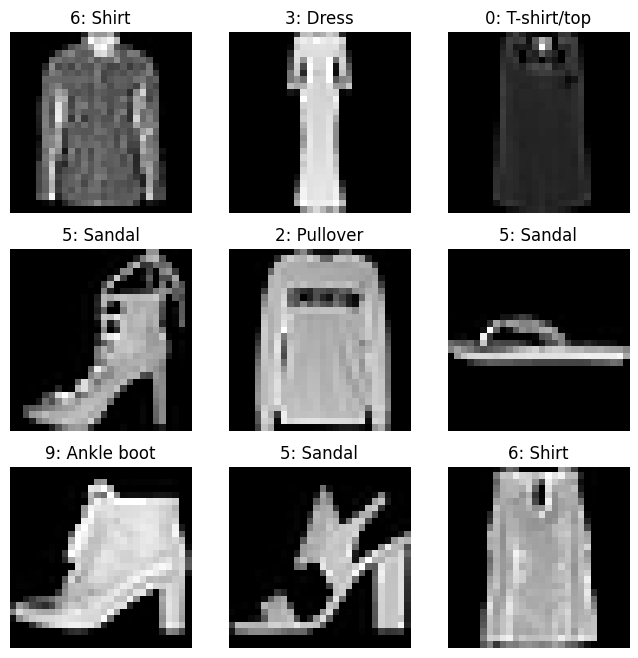

In [41]:
imprimir_imagenes_lote(ds_val.take(3))

In [42]:
def transformacion_de_elemento(image, label):
    # Conversión de u8 -> f32
    p_image = tf.cast(image, dtype = tf.float32)

    # Reescalado [0, 255] -> [0, 1]
    p_image = p_image / 255.0

    return p_image, label



In [43]:
# Prueba de la funcion de transformación
img_prueba, lbl_prueba = next(iter(ds_train.take(1)))
img_out, lbl_out = transformacion_de_elemento(img_prueba, lbl_prueba)

print(f"img_out -> tipo: {img_out.dtype}, rango: [{tf.reduce_min(img_out)},{tf.reduce_max(img_out)}], forma: {img_out.shape}")
print(f"lbl_prueba: {lbl_prueba.dtype}, lbl_out: {lbl_out.dtype}")

img_out -> tipo: <dtype: 'float32'>, rango: [0.0,1.0], forma: (32, 28, 28, 1)
lbl_prueba: <dtype: 'uint8'>, lbl_out: <dtype: 'uint8'>


In [44]:
# Aplicacion de la funcion
ds_train = ds_train.map(transformacion_de_elemento, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
ds_test = ds_test.map(transformacion_de_elemento, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
ds_val = ds_val.map(transformacion_de_elemento, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

# Modelos

In [45]:
img_out.shape

TensorShape([32, 28, 28, 1])

In [46]:
len(class_names)

10

## Modelos con flatten para visualización 2D

In [59]:
def graficas_chidas(history):
    # 1. Graficar la pérdida (Loss)
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Entrenamiento (Loss)')
    plt.plot(history.history['val_loss'], label='Validación (Val_Loss)')
    plt.title('Pérdida del Modelo')
    plt.xlabel('Épocas')
    plt.ylabel('Loss')
    plt.legend()
    
    # 2. Graficar la precisión (Accuracy)
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Entrenamiento (accuracy)')
    plt.plot(history.history['val_accuracy'], label='Validación (Val_accuracy)')
    plt.title('Precisión del Modelo')
    plt.xlabel('Épocas')
    plt.ylabel('Accuracy')
    plt.legend()
    
    plt.show()

In [60]:
def grafica_2D(model, ds):
    # Extractor
    extractor = tf.keras.Model(
        inputs = model.inputs,
        outputs = model.get_layer("rep_2d").output
    )

    # Coordenadas en 2D
    coordenadas = extractor.predict(ds)

    # Obtener etiquetas
    labels = []
    for _, label in ds:
        labels.append(label.numpy())

    labels = np.concatenate(labels, axis = 0)

    scatter_plot = plt.scatter(
        coordenadas[:, 0],
        coordenadas[:, 1],
        c=labels,
        cmap='tab10',
        alpha=0.6,
        s=5
    )

    plt.title("Espacio Latente 2D Aprendido Directamente por el MLP (Sin PCA)")
    plt.xlabel("Neurona de representación 1")
    plt.ylabel("Neurona de representación 2")
    plt.colorbar(scatter_plot, ticks=range(10), label="Dígito")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()

## Intento 1

In [47]:
model_flatten_2d = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 32, activation = "relu"),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])

model_flatten_2d.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
model_flatten_2d.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │            66 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,416 (204.75 KB)

 Trainable params: 52,416 (204.75 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
history_model_flatten_2d = model_flatten_2d.fit(
    ds_train,
    epochs = 15,
    validation_data = ds_val
)

Epoch 1/15


2026-11-19 22:39:20.350484: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 11ms/step - accuracy: 0.6573 - loss: 0.9569 - val_accuracy: 0.7766 - val_loss: 0.7119
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.7991 - loss: 0.6382 - val_accuracy: 0.7954 - val_loss: 0.6306
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.8313 - loss: 0.5416 - val_accuracy: 0.8352 - val_loss: 0.5293
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.8489 - loss: 0.4793 - val_accuracy: 0.8418 - val_loss: 0.4950
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.8562 - loss: 0.4405 - val_accuracy: 0.8476 - val_loss: 0.4801
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8641 - loss: 0.4149 - val_accuracy: 0.8530 - val_loss: 0.4613
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.8694 - loss: 0.3937 - val_accuracy: 0.8520 - val_loss: 0.4734
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.8741 - loss: 0.37

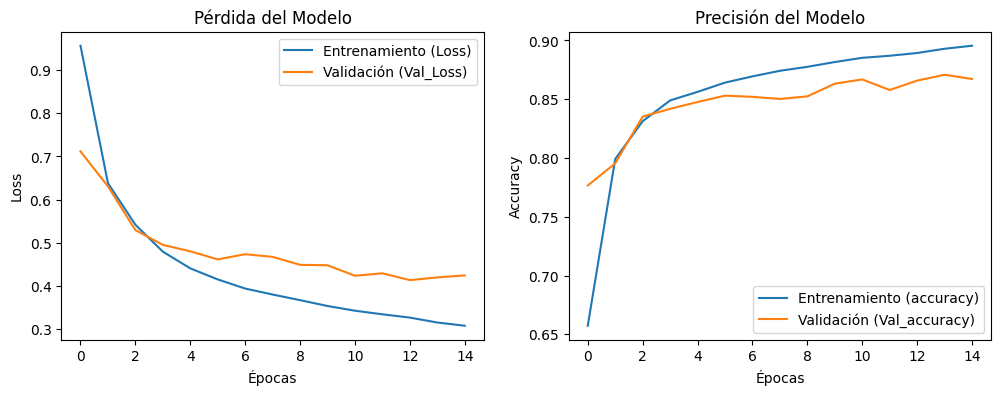

In [51]:
graficas_chidas(history_model_flatten_2d)

 90/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

2026-11-19 22:54:55.333889: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


2026-11-19 22:54:55.702793: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


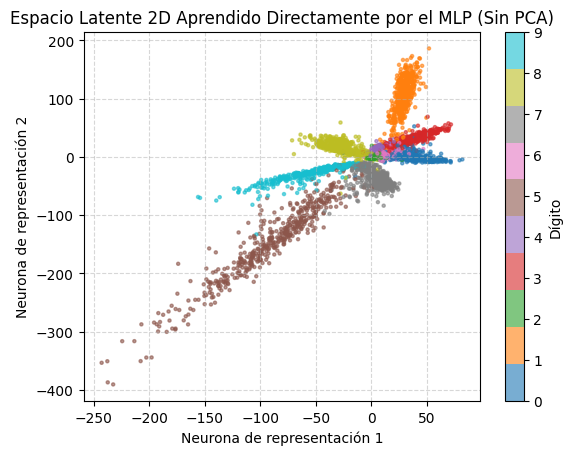

In [62]:
grafica_2D(model_flatten_2d, ds_test)

## Intento 2

In [63]:
model_flatten_2d_2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 32, activation = "relu"),
    tf.keras.layers.Dense(units = 16, activation = "relu"),
    tf.keras.layers.Dense(units = 8, activation = "relu"),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])

model_flatten_2d_2.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [64]:
model_flatten_2d_2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,832 (100.91 KB)

 Trainable params: 25,832 (100.91 KB)

 Non-trainable params: 0 (0.00 B)

In [65]:
history_model_flatten_2d_2 = model_flatten_2d_2.fit(
    ds_train,
    epochs = 15,
    validation_data = ds_val
)

Epoch 1/15


2026-11-19 22:56:18.736059: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 25s 12ms/step - accuracy: 0.6467 - loss: 0.9618 - val_accuracy: 0.7546 - val_loss: 0.7151
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.7859 - loss: 0.6399 - val_accuracy: 0.7986 - val_loss: 0.6115
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8166 - loss: 0.5473 - val_accuracy: 0.8164 - val_loss: 0.5565
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8316 - loss: 0.5002 - val_accuracy: 0.8242 - val_loss: 0.5178
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8397 - loss: 0.4719 - val_accuracy: 0.8304 - val_loss: 0.4978
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8469 - loss: 0.4492 - val_accuracy: 0.8278 - val_loss: 0.5030
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8512 - loss: 0.4332 - val_accuracy: 0.8410 - val_loss: 0.4850
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8565 - loss: 0.42

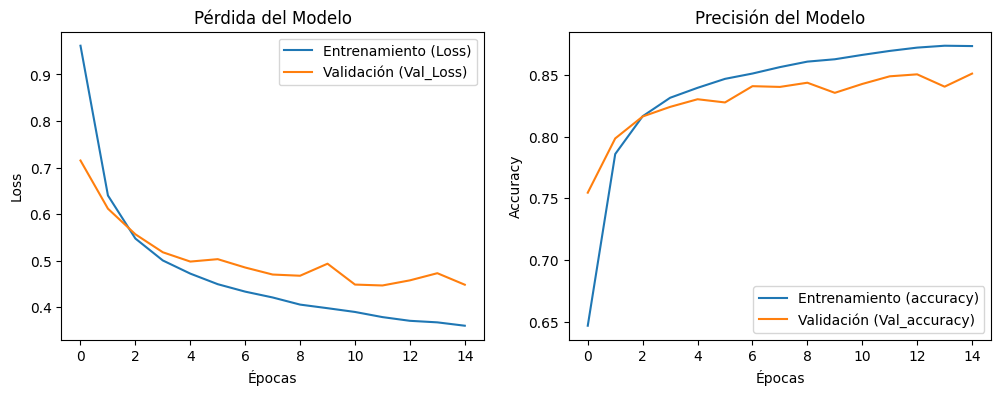

In [66]:
graficas_chidas(history_model_flatten_2d_2)

 95/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

2026-11-19 23:02:08.015031: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


2026-11-19 23:02:08.465823: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


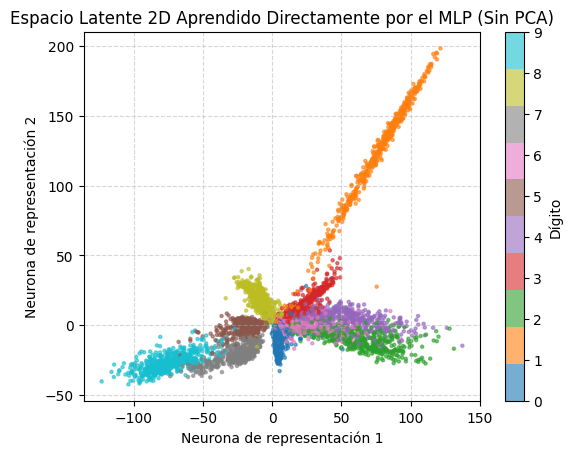

In [67]:
grafica_2D(model_flatten_2d_2, ds_test)

## Intento 3

In [74]:
model_flatten_2d_3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 32, activation = "relu"),
    tf.keras.layers.Dense(units = 8, activation = "relu"),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])

model_flatten_2d_3.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [75]:
model_flatten_2d_3.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,920 (409.84 KB)

 Trainable params: 104,920 (409.84 KB)

 Non-trainable params: 0 (0.00 B)

In [76]:
history_model_flatten_2d_3 = model_flatten_2d_3.fit(
    ds_train,
    epochs = 15,
    validation_data = ds_val
)

Epoch 1/15


2026-11-19 23:12:23.689933: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 25s 13ms/step - accuracy: 0.6608 - loss: 1.0620 - val_accuracy: 0.7460 - val_loss: 0.8177
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.7803 - loss: 0.7656 - val_accuracy: 0.8114 - val_loss: 0.7087
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.8209 - loss: 0.6607 - val_accuracy: 0.8162 - val_loss: 0.7018
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8383 - loss: 0.5900 - val_accuracy: 0.8298 - val_loss: 0.6292
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8514 - loss: 0.5440 - val_accuracy: 0.8400 - val_loss: 0.6296
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8599 - loss: 0.5080 - val_accuracy: 0.8464 - val_loss: 0.6021
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8648 - loss: 0.4740 - val_accuracy: 0.8412 - val_loss: 0.5769
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.8713 - loss: 0.44

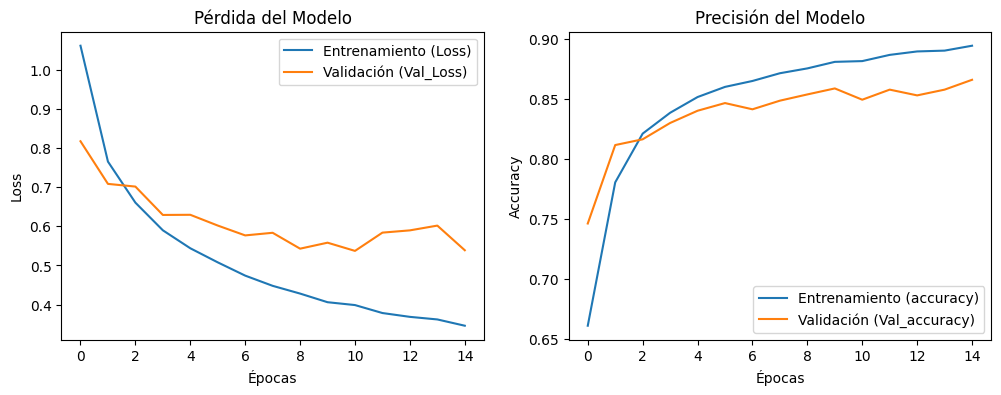

In [77]:
graficas_chidas(history_model_flatten_2d_3)

 63/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

2026-11-19 23:18:14.202474: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


2026-11-19 23:18:14.618820: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


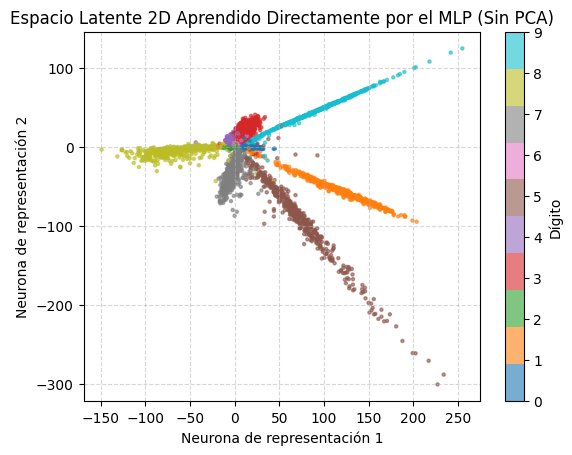

In [78]:
grafica_2D(model_flatten_2d_3, ds_test)